In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)

In [2]:
wave = np.sin(np.linspace(0, 40 * np.pi, 1000)) 
T = 10 
X = np.array([wave[i:i + T] for i in range(len(wave) - T)])    # each row: 10 inputs
y = wave[T:]                                                    # the value that follows

split = int(0.8 * len(X))
X_train, y_train = X[:split], y[:split]
X_test, y_test = X[split:], y[split:]
print(X_train.shape, X_test.shape)

(792, 10) (198, 10)


In [3]:
H, lr = 16, 0.01                      # hidden units, learning rate

Wxh = np.random.randn(H, 1) * 0.1     # input  -> hidden
Whh = np.random.randn(H, H) * 0.1     # hidden -> hidden (the recurrence)
Why = np.random.randn(1, H) * 0.1     # hidden -> output
bh, by = np.zeros((H, 1)), np.zeros((1, 1))

def forward(seq):
    h = np.zeros((H, 1))
    hs = [h]
    for x in seq:                                   # one time step per value
        h = np.tanh(Wxh * x + Whh @ h + bh)         # new hidden state from input + previous state
        hs.append(h)
    return Why @ h + by, hs                         # prediction from the last hidden state

0 0.07237208017430836
5 0.0023626065319586275
10 0.0002896890411694052
15 0.0002371163511952399
20 0.00019473522140128036
25 0.00015621693476196944


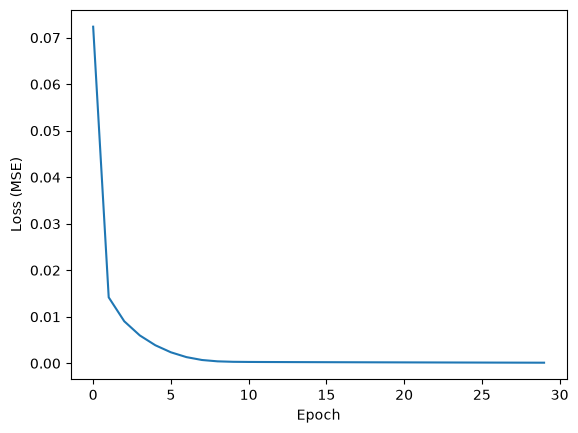

In [4]:
losses = []
for epoch in range(30):
    total = 0
    for seq, target in zip(X_train, y_train):
        pred, hs = forward(seq)
        err = pred - target                         # prediction error
        total += (err ** 2).item()

        # backward pass: walk back through the time steps
        dWxh, dWhh = np.zeros_like(Wxh), np.zeros_like(Whh)
        dbh = np.zeros_like(bh)
        dWhy, dby = err @ hs[-1].T, err
        dh = Why.T @ err
        for t in reversed(range(T)):
            draw = (1 - hs[t + 1] ** 2) * dh        # through tanh
            dWxh += draw * seq[t]
            dWhh += draw @ hs[t].T
            dbh += draw
            dh = Whh.T @ draw                       # pass the gradient to the previous step

        for p, g in [(Wxh, dWxh), (Whh, dWhh), (Why, dWhy), (bh, dbh), (by, dby)]:
            np.clip(g, -1, 1, out=g)                # keep gradients from exploding
            p -= lr * g                             # gradient descent update

    losses.append(total / len(X_train))
    if epoch % 5 == 0:
        print(epoch, losses[-1])

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.show()

Test MSE: 0.0001233178416900932
Baseline MSE (always predict 0): 0.5042412353051143


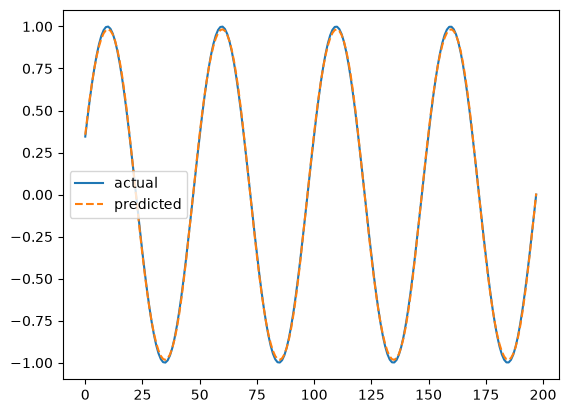

In [5]:
pred_test = np.array([forward(s)[0].item() for s in X_test])

print("Test MSE:", np.mean((pred_test - y_test) ** 2))
print("Baseline MSE (always predict 0):", np.mean(y_test ** 2))

plt.plot(y_test, label="actual")
plt.plot(pred_test, "--", label="predicted")
plt.legend()
plt.show()